# Lab 3 - Task 3: Local Outlier Factor (temporary notebook)

Temporary notebook for Task 3 while Task 2 is developed in `lab3.ipynb`. The setup cells below are copied **unchanged** from `lab3.ipynb` (Task 1 setup, Task 1.2 preprocessing, Task 2 `evaluate` helper); at the merge only the Task 3 sections are moved into `lab3.ipynb`.

In [1]:
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_columns', 60)

TRAIN_PATH, TEST_PATH = 'Lab3_train.csv', 'Lab3_test.csv'
train_raw = pd.read_csv(TRAIN_PATH)
test_raw  = pd.read_csv(TEST_PATH)
print('train', train_raw.shape, '| test', test_raw.shape)

train (18831, 43) | test (5826, 43)


In [2]:
# --- copied from lab3.ipynb, Task 1 / Task 1.2 (feature lists and preprocessing) ---
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, FunctionTransformer

LABEL, BIN = 'label', 'binary_label'
FEATURES = [c for c in train_raw.columns if c not in (LABEL, BIN)]
CAT_COLS = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(train_raw[c])]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
BIN01_COLS = [c for c in NUM_COLS if set(train_raw[c].unique()) <= {0, 1}]

CONST_COLS = [c for c in NUM_COLS if train_raw[c].nunique() == 1]
NUM_KEEP = [c for c in NUM_COLS if c not in CONST_COLS]
RATE_COLS = [c for c in NUM_KEEP if c.endswith('_rate')]
skew = train_raw[NUM_KEEP].skew()
LOG_COLS = [c for c in NUM_KEEP if c not in RATE_COLS and c not in BIN01_COLS and skew[c] > 2]
LIN_COLS = [c for c in NUM_KEEP if c not in LOG_COLS]

def make_preprocessor(scaler_cls):
    return ColumnTransformer([
        ('log_num', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                              ('scale', scaler_cls())]), LOG_COLS),
        ('num', scaler_cls(), LIN_COLS),
        ('cat', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False), CAT_COLS),
    ], remainder='drop', verbose_feature_names_out=True)

preprocessor = make_preprocessor(MinMaxScaler)

# Fit on the full training file only (labels are NOT passed); apply unchanged to test.
X_train = preprocessor.fit_transform(train_raw[FEATURES])
X_test  = preprocessor.transform(test_raw[FEATURES])
FEATURE_NAMES = preprocessor.get_feature_names_out()
y_train_bin, y_test_bin = train_raw[BIN].to_numpy(), test_raw[BIN].to_numpy()
y_train_lab, y_test_lab = train_raw[LABEL].to_numpy(), test_raw[LABEL].to_numpy()
print('X_train', X_train.shape, '| X_test', X_test.shape)

X_train (18831, 106) | X_test (5826, 106)


In [3]:
# --- copied from lab3.ipynb, Task 2 (shared evaluation helper) ---
from sklearn.metrics import f1_score, confusion_matrix

ATTACKS = ['dos', 'probe', 'r2l']

def evaluate(pred_anom, y_bin, y_lab):
    """pred_anom: 1 = flagged anomalous. Returns binary macro-F1, FPR and per-attack recall."""
    tn, fp, fn, tp = confusion_matrix(y_bin, pred_anom, labels=[0, 1]).ravel()
    out = {'macro_f1': f1_score(y_bin, pred_anom, average='macro'), 'FPR': fp / (fp + tn),
           'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
    for a in ATTACKS:
        m = y_lab == a
        if m.any(): out[f'recall_{a}'] = pred_anom[m].mean()
    return out

## Task 3 - Local Outlier Factor

**Knowledge assumed.** LOF is fitted on the **full** training file (normal + all attacks, no labels). The only prior knowledge is the aggregate training contamination (28.6%), used to set the threshold — the same *known-contamination* setting as Task 2. Labels are used only to evaluate.

**Score and threshold.** For each point, LOF = average local reachability density of its `n_neighbors` neighbours / its own density: ≈ 1 means "as dense as its neighbours", > 1 means lower density than its neighbours. With `contamination = 0.286` the threshold is the LOF value above which 28.6% of the training points lie. As a comparison that costs no extra fit, we also apply sklearn's `contamination='auto'` threshold (LOF > 1.5, i.e. no knowledge of the contamination) to the same scores.

**`n_neighbors` sweep (logbook run 8, one diagnostic run).** Four values, log-spaced to include the extremes: **5** (very local density), **20** (sklearn default), **100**, **500** (larger than the whole r2l class, 181 rows, and comparable with groups of repeated DoS connections). Distance: Euclidean on the 106 preprocessed features.

**Selection criterion.** Highest binary macro-F1 on the training file, checked against the threshold-free ROC-AUC of the LOF score (to separate ranking quality from the threshold), and explained through the per-attack recall.

In [4]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score, average_precision_score

K_VALUES = [5, 20, 100, 500]
CONT_TRAIN = y_train_bin.mean()
LOF_RES, LOF_SCORE = {}, {}

for k in K_VALUES:
    t0 = time.perf_counter()
    lof = LocalOutlierFactor(n_neighbors=k, contamination=CONT_TRAIN)
    pred = (lof.fit_predict(X_train) == -1).astype(int)
    fit_s = time.perf_counter() - t0
    score = -lof.negative_outlier_factor_                     # LOF value: > 1 = lower density than neighbours
    res = evaluate(pred, y_train_bin, y_train_lab)
    res.update({'flagged': pred.mean(), 'LOF_threshold': -lof.offset_,
                'ROC_AUC': roc_auc_score(y_train_bin, score), 'AP': average_precision_score(y_train_bin, score),
                'fit_s': fit_s})
    auto = evaluate((score > 1.5).astype(int), y_train_bin, y_train_lab)  # contamination='auto' threshold
    res.update({'auto_flagged': (score > 1.5).mean(), 'auto_macro_f1': auto['macro_f1'], 'auto_FPR': auto['FPR']})
    LOF_RES[k], LOF_SCORE[k] = res, score
    print(f'k={k:>3}: fit {fit_s:5.1f}s | threshold LOF>{res["LOF_threshold"]:.3f} | macro-F1={res["macro_f1"]:.4f}, '
          f'FPR={res["FPR"]:.4f}, AUC={res["ROC_AUC"]:.4f} | '
          + ', '.join(f'{a}={res[f"recall_{a}"]:.3f}' for a in ATTACKS))

sweep = pd.DataFrame(LOF_RES).T
sweep.index.name = 'n_neighbors'
display(sweep[['flagged', 'LOF_threshold', 'macro_f1', 'FPR', 'recall_dos', 'recall_probe', 'recall_r2l',
               'ROC_AUC', 'AP', 'FP', 'FN', 'fit_s']].astype(float).round(4))
print('Same scores, contamination="auto" threshold (LOF > 1.5):')
display(sweep[['auto_flagged', 'auto_macro_f1', 'auto_FPR']].astype(float).round(4))

k=  5: fit   0.5s | threshold LOF>1.139 | macro-F1=0.5145, FPR=0.2776, AUC=0.4972 | dos=0.292, probe=0.317, r2l=0.414


k= 20: fit   0.4s | threshold LOF>1.138 | macro-F1=0.5294, FPR=0.2690, AUC=0.5127 | dos=0.340, probe=0.310, r2l=0.359


k=100: fit   0.5s | threshold LOF>1.236 | macro-F1=0.5774, FPR=0.2416, AUC=0.5933 | dos=0.533, probe=0.240, r2l=0.166


k=500: fit   1.6s | threshold LOF>1.267 | macro-F1=0.5224, FPR=0.2731, AUC=0.4876 | dos=0.447, probe=0.148, r2l=0.381


,flagged,LOF_threshold,macro_f1,FPR,recall_dos,recall_probe,recall_r2l,ROC_AUC,AP,FP,FN,fit_s
n_neighbors,,,,,,,,,,,,
5,0.2859,1.1393,0.5145,0.2776,0.2918,0.3167,0.4144,0.4972,0.3240,3733.0,3733.0,0.4940
20,0.2859,1.1384,0.5294,0.2690,0.3399,0.3102,0.3591,0.5127,0.3588,3618.0,3618.0,0.4257
100,0.2859,1.2363,0.5774,0.2416,0.5335,0.2403,0.1657,0.5933,0.4475,3249.0,3249.0,0.5106
500,0.2859,1.2673,0.5224,0.2731,0.4473,0.1481,0.3812,0.4876,0.3116,3672.0,3672.0,1.5976


Same scores, contamination="auto" threshold (LOF > 1.5):


,auto_flagged,auto_macro_f1,auto_FPR
n_neighbors,,,
5,0.1057,0.4984,0.0950
20,0.1243,0.5339,0.0996
100,0.1854,0.5829,0.1401
500,0.2226,0.5539,0.1926


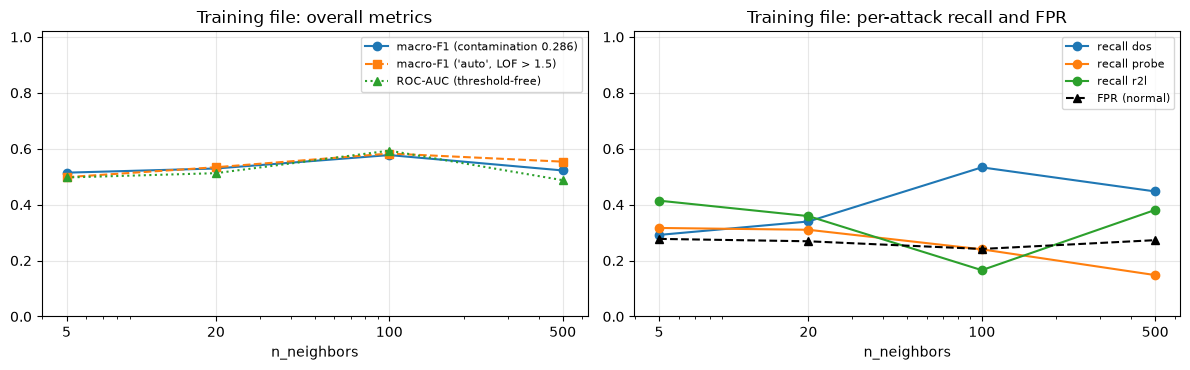

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(K_VALUES, sweep['macro_f1'], 'o-', label='macro-F1 (contamination 0.286)')
axes[0].plot(K_VALUES, sweep['auto_macro_f1'], 's--', label="macro-F1 ('auto', LOF > 1.5)")
axes[0].plot(K_VALUES, sweep['ROC_AUC'], '^:', label='ROC-AUC (threshold-free)')
axes[0].set_title('Training file: overall metrics')
for a in ATTACKS:
    axes[1].plot(K_VALUES, sweep[f'recall_{a}'], 'o-', label=f'recall {a}')
axes[1].plot(K_VALUES, sweep['FPR'], 'k^--', label='FPR (normal)')
axes[1].set_title('Training file: per-attack recall and FPR')
for ax in axes:
    ax.set_xscale('log'); ax.set_xticks(K_VALUES); ax.set_xticklabels(K_VALUES)
    ax.set_xlabel('n_neighbors'); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Do attacks have lower local density than their neighbours?** Distribution of the LOF value per label for each `n_neighbors` (log scale; red line = known-contamination threshold). A class is detected only if its LOF values lie above the line, i.e. if its points are *sparser than their own neighbours* — not merely far from normal traffic.

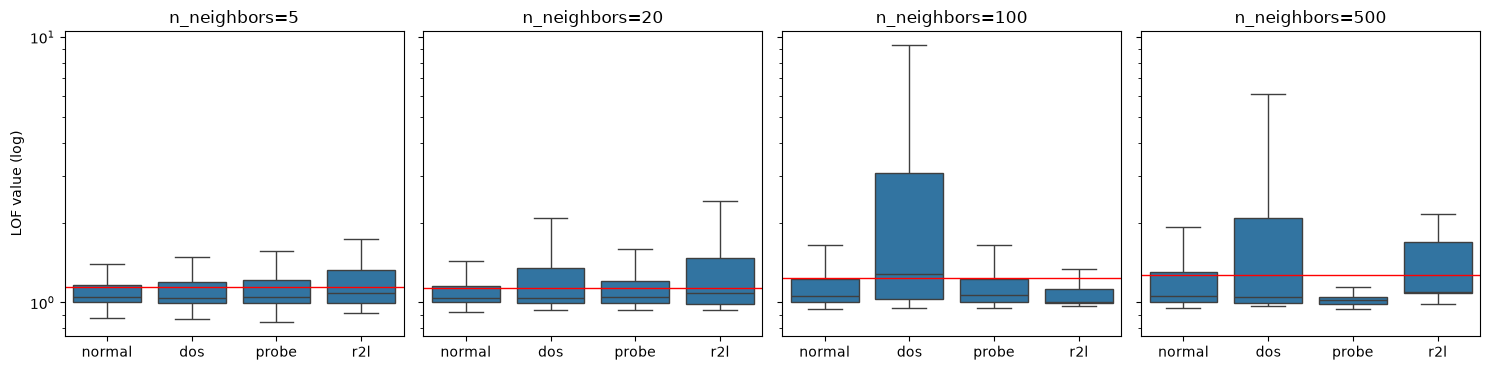

Median LOF value per label:


n_neighbors,5,20,100,500
normal,1.046,1.044,1.059,1.061
dos,1.041,1.042,1.275,1.051
probe,1.047,1.045,1.062,1.020
r2l,1.087,1.088,1.000,1.095


In [6]:
ORDER = ['normal', 'dos', 'probe', 'r2l']
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(15, 3.8), sharey=True)
for ax, k in zip(axes, K_VALUES):
    df = pd.DataFrame({'label': y_train_lab, 'LOF': LOF_SCORE[k]})
    sns.boxplot(data=df, x='label', y='LOF', order=ORDER, ax=ax, showfliers=False)
    ax.axhline(LOF_RES[k]['LOF_threshold'], color='red', lw=1)
    ax.set_yscale('log'); ax.set_title(f'n_neighbors={k}'); ax.set_xlabel('')
axes[0].set_ylabel('LOF value (log)')
plt.tight_layout(); plt.show()

med = pd.DataFrame({k: pd.Series(LOF_SCORE[k]).groupby(y_train_lab).median() for k in K_VALUES}).loc[ORDER]
med.columns.name = 'n_neighbors'
print('Median LOF value per label:')
display(med.round(3))

In [7]:
K_STAR = int(sweep['macro_f1'].astype(float).idxmax())
print(f'Selected n_neighbors = {K_STAR} (highest training macro-F1; ROC-AUC {LOF_RES[K_STAR]["ROC_AUC"]:.4f})')

Selected n_neighbors = 100 (highest training macro-F1; ROC-AUC 0.5933)


### Task 3 - Test evaluation (logbook run 9)

The selected configuration is refitted on the full training file with `novelty=True`: in sklearn this is required to score **new** points (`fit_predict` only labels the data it was fitted on). The threshold is still the one implied by the training contamination (28.6%), while the test contamination is 63.1%.

n_neighbors=100, fit 0.6s | test macro-F1=0.5691, FPR=0.3518, AUC=0.6053, flagged=0.463 | dos=0.611, probe=0.336


,pred normal,pred anomaly
true normal,1395,757
true anomaly,1731,1943


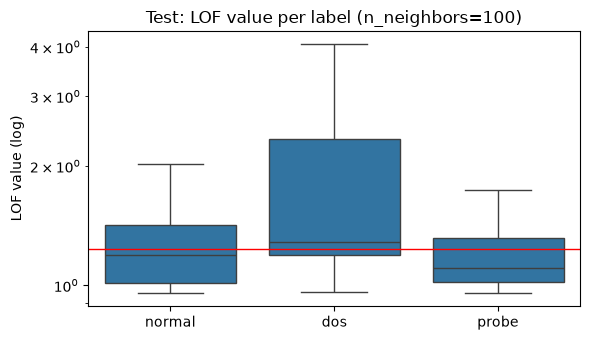

In [8]:
t0 = time.perf_counter()
lof_final = LocalOutlierFactor(n_neighbors=K_STAR, contamination=CONT_TRAIN, novelty=True).fit(X_train)
fit_s = time.perf_counter() - t0
test_score = -lof_final.score_samples(X_test)
pred_test = (lof_final.predict(X_test) == -1).astype(int)
res_test = evaluate(pred_test, y_test_bin, y_test_lab)
res_test.update({'flagged': pred_test.mean(), 'ROC_AUC': roc_auc_score(y_test_bin, test_score), 'fit_s': fit_s})
print(f'n_neighbors={K_STAR}, fit {fit_s:.1f}s | test macro-F1={res_test["macro_f1"]:.4f}, FPR={res_test["FPR"]:.4f}, '
      f'AUC={res_test["ROC_AUC"]:.4f}, flagged={res_test["flagged"]:.3f} | '
      + ', '.join(f'{a}={res_test[f"recall_{a}"]:.3f}' for a in ATTACKS if f'recall_{a}' in res_test))
display(pd.DataFrame([[res_test['TN'], res_test['FP']], [res_test['FN'], res_test['TP']]],
                     index=['true normal', 'true anomaly'], columns=['pred normal', 'pred anomaly']))

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(x=y_test_lab, y=test_score, order=['normal', 'dos', 'probe'], showfliers=False, ax=ax)
ax.axhline(-lof_final.offset_, color='red', lw=1); ax.set_yscale('log')
ax.set_title(f'Test: LOF value per label (n_neighbors={K_STAR})'); ax.set_ylabel('LOF value (log)')
plt.tight_layout(); plt.show()